# Clasificación de tumores de mama (Wisconsin): EDA y comparación de modelos

**Notebook común.** Contiene el análisis exploratorio (EDA) y la preparación de datos, una única vez para los tres modelos.
Incluye la comparación de `reg_bin`, `svm` y `log_pol` (sección 7) y la calibración, el umbral clínico y la exportación del modelo que usa la aplicación (sección 9).

**Orden de ejecución:** primero `reg_bin/reg_bin.ipynb`, `svm/svm.ipynb` y `log_pol/log_pol.ipynb` (exportan sus pipelines), después este notebook de principio a fin.

## 1. Contexto y pregunta de negocio
Dadas las características medidas de una muestra de biopsia (núcleos celulares digitalizados), ¿el tumor es **benigno (B)** o **maligno (M)**?

**Por qué importa:** un *falso negativo* (maligno clasificado como benigno) retrasa un tratamiento y es mucho más costoso que un *falso positivo* (que lleva a más pruebas).
Por eso, además de la exactitud, priorizaremos el **recall de la clase maligna**.

- Dataset: *Breast Cancer Wisconsin (Diagnostic)* — Kaggle `uciml/breast-cancer-wisconsin-data`.
- Modelos a comparar: Regresión Logística Binaria, SVM (RBF) y Regresión Logística Polinomial (grado 2).

In [1]:
# Librerías y configuración general
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42          # semilla fija para reproducibilidad

## 2. Carga y estructura de los datos

In [2]:
# El notebook vive en backend/models/, el dataset en data/data.csv (dos niveles arriba)
from pathlib import Path
DATA_PATH = Path("..") / ".." / "data" / "data.csv"

df = pd.read_csv(DATA_PATH)
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (569, 33)


,id,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,...,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst,Unnamed: 32
0,842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890,NaN
1,842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902,NaN
2,84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758,NaN
3,84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300,NaN
4,84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678,NaN


In [3]:
# Tipos de dato y nulos por columna
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 569 entries, 0 to 568
Data columns (total 33 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   id                       569 non-null    int64  
 1   diagnosis                569 non-null    str    
 2   radius_mean              569 non-null    float64
 3   texture_mean             569 non-null    float64
 4   perimeter_mean           569 non-null    float64
 5   area_mean                569 non-null    float64
 6   smoothness_mean          569 non-null    float64
 7   compactness_mean         569 non-null    float64
 8   concavity_mean           569 non-null    float64
 9   concave points_mean      569 non-null    float64
 10  symmetry_mean            569 non-null    float64
 11  fractal_dimension_mean   569 non-null    float64
 12  radius_se                569 non-null    float64
 13  texture_se               569 non-null    float64
 14  perimeter_se             569 non-null

Las 30 variables numéricas son 10 medidas del núcleo celular, cada una en tres versiones:
**`_mean`** (promedio), **`_se`** (error estándar) y **`_worst`** (promedio de los 3 valores más grandes).
`diagnosis` es el objetivo (M/B), `id` es solo un identificador.

## 3. Calidad de datos: nulos, duplicados y atípicos

In [4]:
# Columnas con valores faltantes
nulos = df.isna().sum()
print(nulos[nulos > 0])

# Duplicados (filas y ids)
print("\nFilas duplicadas:", df.duplicated().sum())
print("IDs duplicados:", df["id"].duplicated().sum())

Unnamed: 32    569
dtype: int64

Filas duplicadas: 0
IDs duplicados: 0


La cabecera del CSV termina en coma, lo que genera una columna extra vacía (`Unnamed: 32`).
Se eliminará junto con `id`, que no aporta información predictiva.

In [5]:
# Limpieza: quitar id y cualquier columna sin nombre/vacía
cols_basura = ["id"] + [c for c in df.columns if c.startswith("Unnamed")]
df = df.drop(columns=cols_basura)
print("Columnas eliminadas:", cols_basura)
print("Nulos restantes:", int(df.isna().sum().sum()))
print("Dimensiones:", df.shape)

Columnas eliminadas: ['id', 'Unnamed: 32']
Nulos restantes: 0
Dimensiones: (569, 31)


In [6]:
# Atípicos por regla del IQR (1.5 * IQR) en cada variable numérica
num_cols = df.drop(columns="diagnosis").columns
q1, q3 = df[num_cols].quantile(0.25), df[num_cols].quantile(0.75)
iqr = q3 - q1
atipicos = ((df[num_cols] < q1 - 1.5 * iqr) | (df[num_cols] > q3 + 1.5 * iqr)).sum()
print("Variables con más atípicos:")
print(atipicos.sort_values(ascending=False).head(10))
print(f"\nFilas con al menos un atípico: {((df[num_cols] < q1 - 1.5*iqr) | (df[num_cols] > q3 + 1.5*iqr)).any(axis=1).sum()} de {len(df)}")

Variables con más atípicos:
area_se                    65
radius_se                  38
perimeter_se               38
area_worst                 35
smoothness_se              30
fractal_dimension_se       28
compactness_se             28
symmetry_se                27
area_mean                  25
fractal_dimension_worst    24
dtype: int64

Filas con al menos un atípico: 171 de 569


Hay atípicos, pero en este dominio son **mediciones reales de tumores grandes o irregulares**, típicamente malignos, no errores de captura.
**Decisión:** no se eliminan (se perdería información clínica relevante). En su lugar se usará `StandardScaler` y modelos con regularización, que son razonablemente robustos.

## 4. Distribución de la variable objetivo (balance de clases)

diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7 %
M    37.3 %
Name: proportion, dtype: str


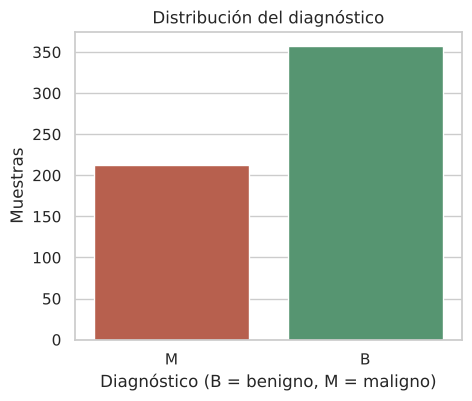

In [7]:
conteo = df["diagnosis"].value_counts()
print(conteo)
print((df["diagnosis"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

fig, ax = plt.subplots(figsize=(5, 4))
sns.countplot(data=df, x="diagnosis", hue="diagnosis", palette={"B": "#4C9F70", "M": "#C8553D"}, legend=False, ax=ax)
ax.set_title("Distribución del diagnóstico")
ax.set_xlabel("Diagnóstico (B = benigno, M = maligno)")
ax.set_ylabel("Muestras")
plt.show()

Las clases están **moderadamente desbalanceadas** (≈ 63 % benigno / 37 % maligno). No es un desbalance severo, así que no hace falta remuestreo,
pero sí: (1) **estratificar** el split y la validación cruzada, y (2) **no juzgar solo por accuracy**; un modelo que dijera siempre "benigno" ya obtendría ≈ 63 %.

## 5. Visualizaciones

### 5.1 Distribución de variables clave por clase

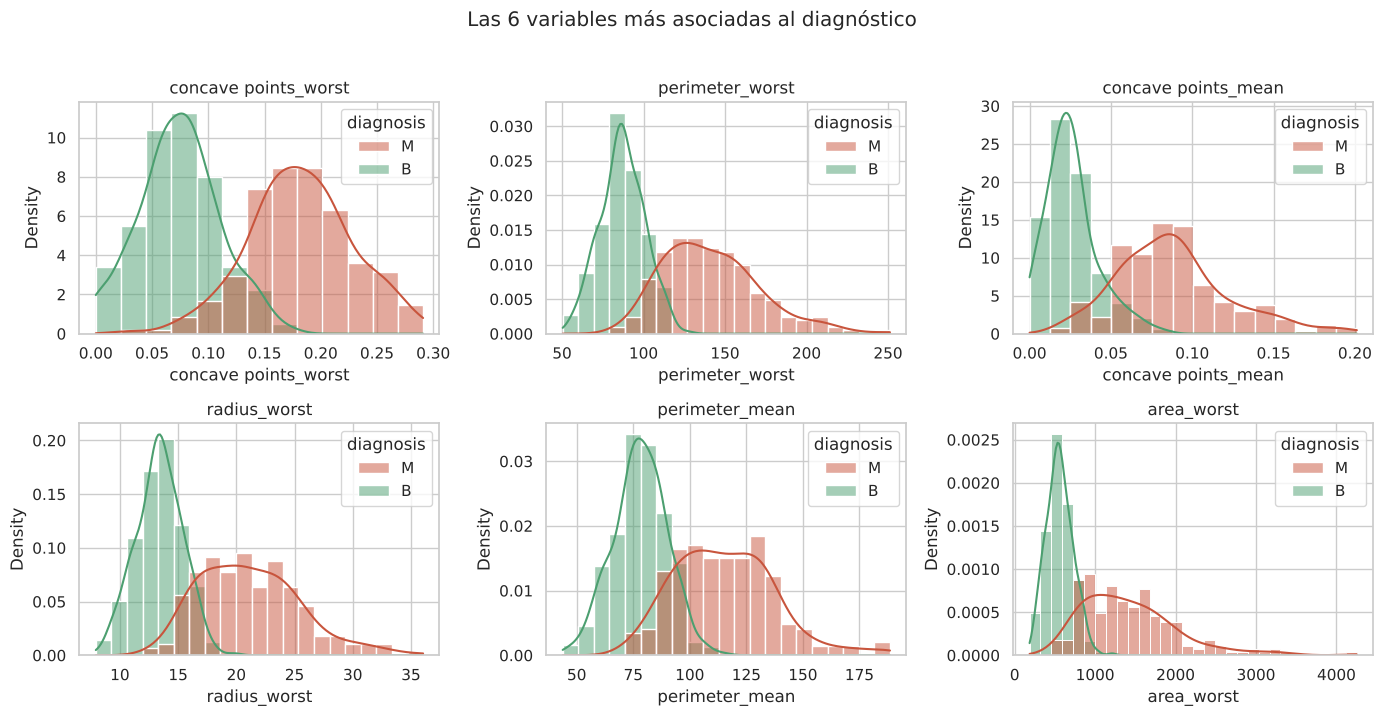

In [8]:
# Las variables _mean suelen ser las más interpretables; vemos las 6 que más separan las clases
y_num = df["diagnosis"].map({"B": 0, "M": 1})
sep = df[num_cols].corrwith(y_num).abs().sort_values(ascending=False)
top6 = list(sep.head(6).index)

fig, axes = plt.subplots(2, 3, figsize=(14, 7))
for ax, col in zip(axes.ravel(), top6):
    sns.histplot(data=df, x=col, hue="diagnosis", kde=True, stat="density", common_norm=False,
                 palette={"B": "#4C9F70", "M": "#C8553D"}, ax=ax)
    ax.set_title(col)
plt.suptitle("Las 6 variables más asociadas al diagnóstico", y=1.02)
plt.tight_layout()
plt.show()

Las variables de **tamaño** (`radius`, `perimeter`, `area`) y de **concavidad** (`concave points`) separan muy bien ambas clases: los tumores malignos tienden a ser mayores y más irregulares.

### 5.2 Boxplots por clase

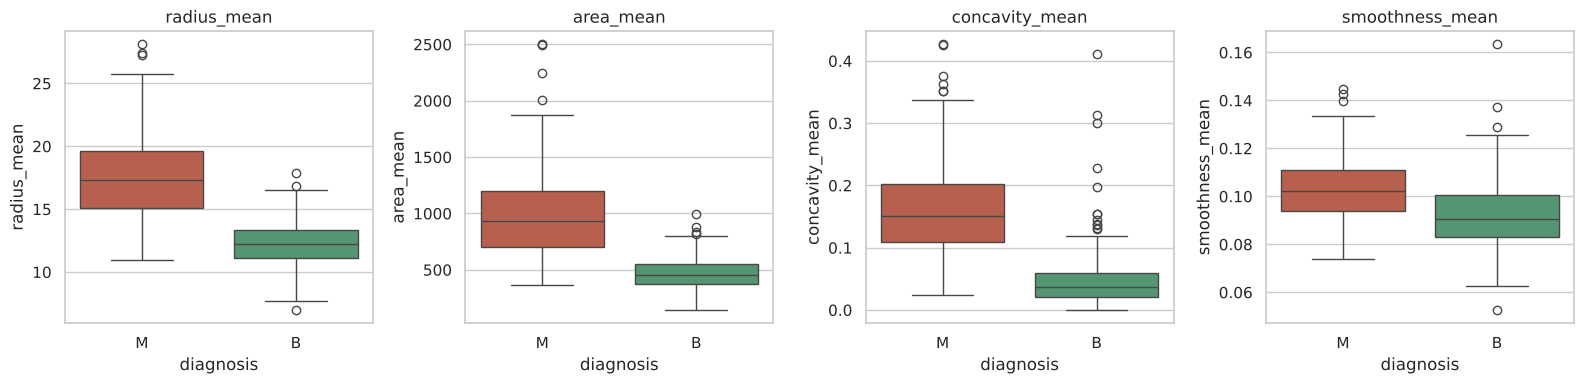

In [9]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))
for ax, col in zip(axes, ["radius_mean", "area_mean", "concavity_mean", "smoothness_mean"]):
    sns.boxplot(data=df, x="diagnosis", y=col, hue="diagnosis",
                palette={"B": "#4C9F70", "M": "#C8553D"}, legend=False, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

Los boxplots confirman la separación y muestran los atípicos (puntos) concentrados sobre todo en la clase maligna.

### 5.3 Matriz de correlación (multicolinealidad)

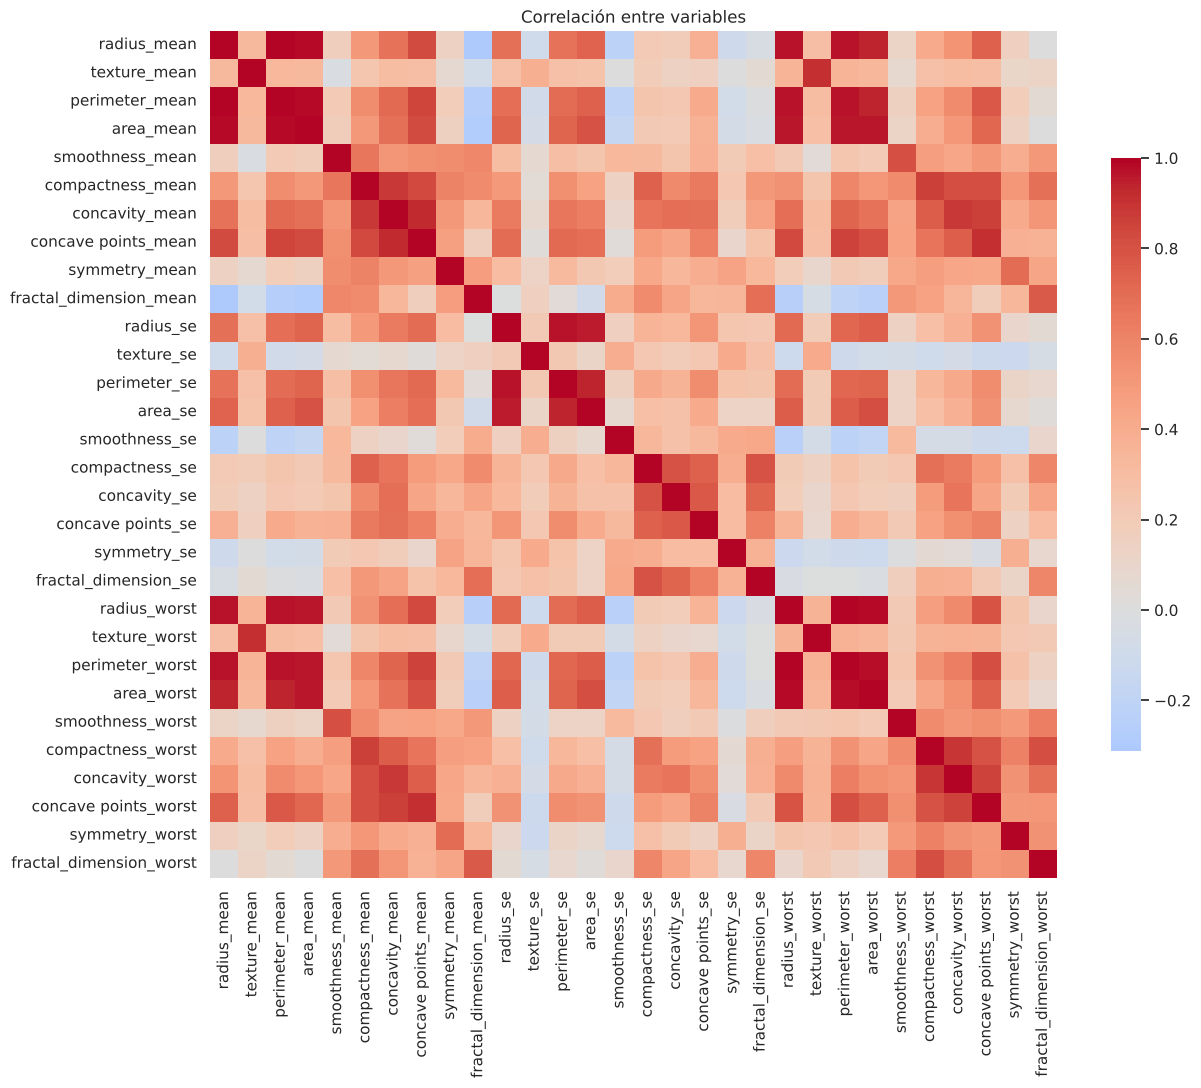

Pares con |r| > 0.95: 15


radius_mean      perimeter_mean     0.997855
radius_worst     perimeter_worst    0.993708
radius_mean      area_mean          0.987357
perimeter_mean   area_mean          0.986507
radius_worst     area_worst         0.984015
perimeter_worst  area_worst         0.977578
radius_se        perimeter_se       0.972794
perimeter_mean   perimeter_worst    0.970387
radius_mean      radius_worst       0.969539
perimeter_mean   radius_worst       0.969476
dtype: float64

In [10]:
corr = df[num_cols].corr()
fig, ax = plt.subplots(figsize=(14, 11))
sns.heatmap(corr, cmap="coolwarm", center=0, square=True, cbar_kws={"shrink": 0.7}, ax=ax)
ax.set_title("Correlación entre variables")
plt.show()

# Pares muy correlacionados (|r| > 0.95), cada par contado una vez
pares = (corr.where(np.triu(np.ones(corr.shape), k=1).astype(bool))
             .stack().loc[lambda s: s.abs() > 0.95].sort_values(ascending=False))
print(f"Pares con |r| > 0.95: {len(pares)}")
pares.head(10)

Existe **fuerte multicolinealidad** (p. ej. `radius`, `perimeter` y `area` son casi la misma información). Consecuencias para el modelado:
- La **regresión logística** necesita **regularización** (parámetro `C`) para estabilizar coeficientes.
- **SVM** es menos sensible a este problema.
- En `log_pol` (grado 2) la regularización es aún más importante: se pasa de 30 a ~500 variables.
- Todas las variables deben **escalarse** (rangos muy distintos: `area` ~ 10³ frente a `smoothness` ~ 10⁻¹).

## 6. Preparación de datos
1. Variable objetivo codificada: **M = 1 (positivo), B = 0**.
2. Split **80/20 estratificado** con `random_state=42` (idéntico en los tres notebooks de modelo).
3. El **escalado no se hace aquí**: irá dentro de cada `Pipeline` para que se ajuste solo con *train* y no haya fuga de datos (*data leakage*).

In [11]:
X = df.drop(columns="diagnosis")
y = df["diagnosis"].map({"B": 0, "M": 1})

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=RANDOM_STATE, stratify=y
)

print("Train:", X_train.shape, "| Test:", X_test.shape)
print("Proporción de maligno -> train: %.3f | test: %.3f" % (y_train.mean(), y_test.mean()))

Train: (455, 30) | Test: (114, 30)
Proporción de maligno -> train: 0.374 | test: 0.368


**Snippet de preparación reutilizable** (se copiará al inicio de `reg_bin.ipynb`, `svm.ipynb` y `log_pol.ipynb`):

```python
df = pd.read_csv("../../data/data.csv")
df = df.drop(columns=["id"] + [c for c in df.columns if c.startswith("Unnamed")])
X = df.drop(columns="diagnosis"); y = df["diagnosis"].map({"B": 0, "M": 1})
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
```

## 7. Comparación final de modelos
Se cargan los tres **pipelines exportados** (`reg_bin`, `svm`, `log_pol`) y se comparan sobre:
1. el **conjunto de prueba** (20 %, 114 muestras), que ningún modelo vio durante el entrenamiento ni el tuning;
2. una **validación cruzada 5×5** sobre las 569 muestras, con los mismos folds para todos, porque el test tiene solo 42 casos malignos y es muy ruidoso.

Resumen completo y recomendación en `COMPARACION_RESULTADOS.md`.

In [12]:
import joblib, json
from sklearn.base import clone
from sklearn.model_selection import RepeatedStratifiedKFold, cross_validate
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix, RocCurveDisplay,
                             ConfusionMatrixDisplay)

MODELOS = {"reg_bin": "Regresión Logística", "svm": "SVM (RBF)", "log_pol": "Log. Polinomial (g=2)"}
from pathlib import Path
faltan = [m for m in MODELOS if not Path(f"{m}/pipeline/pipeline.pkl").exists()]
assert not faltan, f"Ejecute primero los notebooks de: {faltan}"
pipes = {m: joblib.load(f"{m}/pipeline/pipeline.pkl") for m in MODELOS}   # Pipelines completos exportados

### 7.1 Métricas en el conjunto de prueba

In [13]:
filas, probas = {}, {}
for m, p in pipes.items():
    pred = p.predict(X_test)
    probas[m] = p.predict_proba(X_test)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, pred).ravel()
    filas[m] = {"Accuracy": accuracy_score(y_test, pred), "Precision": precision_score(y_test, pred),
                "Recall (maligno)": recall_score(y_test, pred), "F1": f1_score(y_test, pred),
                "ROC-AUC": roc_auc_score(y_test, probas[m]), "Falsos negativos": fn, "Falsos positivos": fp}
tabla_test = pd.DataFrame(filas).T
tabla_test.round(4)

,Accuracy,Precision,Recall (maligno),F1,ROC-AUC,Falsos negativos,Falsos positivos
reg_bin,0.9825,1.0000,0.9524,0.9756,0.9980,2.0,0.0
svm,0.9737,1.0000,0.9286,0.9630,0.9927,3.0,0.0
log_pol,0.9386,0.9268,0.9048,0.9157,0.9914,4.0,3.0


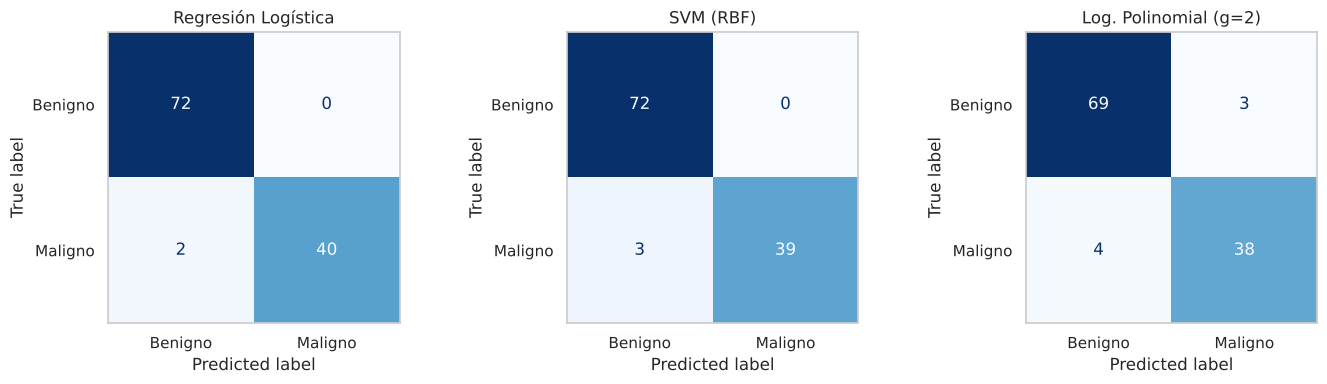

In [14]:
# Matrices de confusión lado a lado
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, (m, p) in zip(axes, pipes.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, p.predict(X_test), display_labels=["Benigno", "Maligno"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(MODELOS[m]); ax.grid(False)
plt.tight_layout(); plt.show()

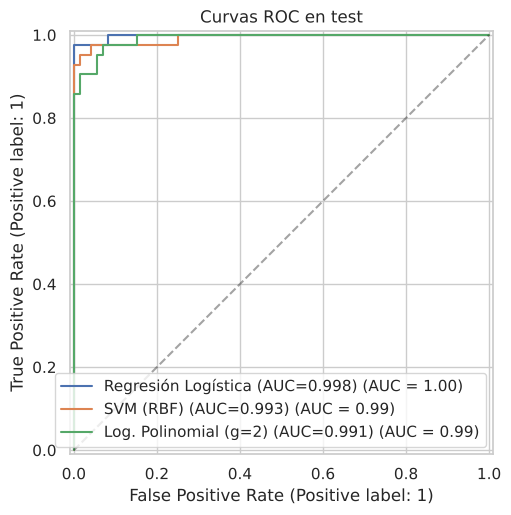

In [15]:
# Curvas ROC superpuestas
fig, ax = plt.subplots(figsize=(6.5, 5.5))
for m in MODELOS:
    RocCurveDisplay.from_predictions(y_test, probas[m], name=f"{MODELOS[m]} (AUC={roc_auc_score(y_test, probas[m]):.3f})", ax=ax)
ax.plot([0, 1], [0, 1], "k--", alpha=.4)
ax.set_title("Curvas ROC en test")
plt.show()

**Lectura del test:** `reg_bin` obtiene el mejor resultado (2 falsos negativos), `svm` queda muy cerca (3) y `log_pol` es el peor (4 falsos negativos y 3 falsos positivos).
La *precision* de 1.000 de los dos primeros solo indica **cero falsos positivos en estas 114 muestras**, no un modelo perfecto.

### 7.2 Validación cruzada 5×5 sobre todo el dataset

In [16]:
# Mismos folds para los tres modelos -> comparación pareada justa
cv = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=7)
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

resumen, f1_folds = {}, {}
for m, p in pipes.items():
    r = cross_validate(clone(p), X, y, cv=cv, scoring=scoring, n_jobs=1)   # clone: se reentrena de cero en cada fold
    resumen[m] = {s: f"{r['test_'+s].mean():.4f} ± {r['test_'+s].std():.3f}" for s in scoring}
    f1_folds[m] = r["test_f1"]
pd.DataFrame(resumen).T.rename(columns={"recall": "recall (maligno)"})

,accuracy,precision,recall (maligno),f1,roc_auc
reg_bin,0.9761 ± 0.016,0.9820 ± 0.025,0.9537 ± 0.029,0.9673 ± 0.022,0.9942 ± 0.006
svm,0.9743 ± 0.015,0.9699 ± 0.025,0.9612 ± 0.025,0.9653 ± 0.020,0.9941 ± 0.005
log_pol,0.9663 ± 0.021,0.9610 ± 0.043,0.9498 ± 0.026,0.9548 ± 0.027,0.9917 ± 0.010


reg_bin  vs svm      | dif. media F1 = +0.0020 | gana 13, empata  2, pierde 10 de 25
reg_bin  vs log_pol  | dif. media F1 = +0.0126 | gana 14, empata  4, pierde  7 de 25
svm      vs log_pol  | dif. media F1 = +0.0105 | gana 17, empata  5, pierde  3 de 25


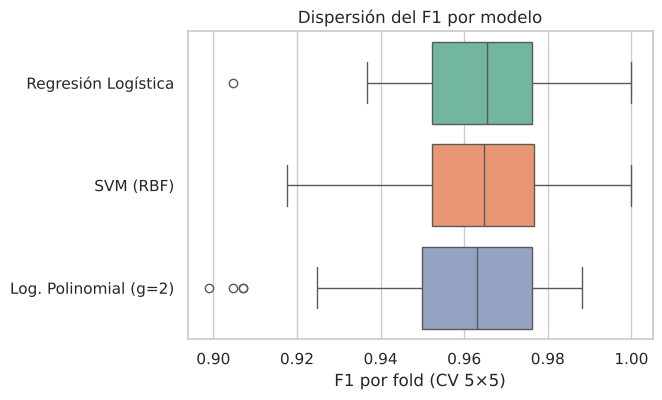

In [17]:
# Comparación pareada de F1, fold a fold
import itertools
for a, b in itertools.combinations(MODELOS, 2):
    d = f1_folds[a] - f1_folds[b]
    print(f"{a:8s} vs {b:8s} | dif. media F1 = {d.mean():+.4f} | gana {int((d>0).sum()):2d}, empata {int((d==0).sum()):2d}, pierde {int((d<0).sum()):2d} de {len(d)}")

plt.figure(figsize=(6, 4))
sns.boxplot(data=pd.DataFrame(f1_folds).rename(columns=MODELOS), orient="h", palette="Set2")
plt.xlabel("F1 por fold (CV 5×5)"); plt.title("Dispersión del F1 por modelo")
plt.show()

## 8. Selección preliminar (umbral 0.5, criterio F1)
- **`reg_bin` y `svm` están técnicamente empatados**: la diferencia de F1 en CV (≈ 0.002) es mucho menor que la variación entre folds (≈ 0.02). `reg_bin` gana en test; `svm` tiene algo más de recall en CV.
- **`log_pol` es el más débil**: pasar de 30 a 495 variables no aportó información útil, porque los datos ya son casi linealmente separables (visto en el EDA).
- **Selección preliminar: `reg_bin`.** Ante un empate estadístico se prefiere el más simple e interpretable. `svm` es la alternativa si se priorizara minimizar falsos negativos.
- Esta comparación usa el umbral por defecto (0.5) y modelos ajustados por F1. La aplicación muestra **probabilidades** y su prioridad es **no dejar pasar malignos**, así que en la sección 9 se revisa la elección con esos dos criterios.

*Nota:* los hiperparámetros se eligieron con el 80 % de los datos que también está en la CV, por lo que esas cifras son algo optimistas (igual para los tres modelos); sirven para comparar, no como estimación definitiva.

## 9. Calibración, umbral clínico y modelo final de la aplicación

La sección 8 eligió con dos supuestos que no encajan del todo con el uso real de la app:

1. **Umbral 0.5.** En cribado oncológico un falso negativo cuesta mucho más que un falso positivo. Conviene fijar el umbral para alcanzar una sensibilidad objetivo (98 %), no dejarlo en 0.5.
2. **Criterio F1.** La app muestra al usuario la **probabilidad** de malignidad. Si el modelo está mal calibrado, un "70 %" no significa 70 %. Hace falta medir la **calibración** (Brier score y ECE) y ajustar los hiperparámetros con una métrica que la premie (**log-loss**).

Todo lo de esta sección usa solo el conjunto de entrenamiento (validación cruzada 5×5). El test se evalúa una sola vez al final. El código vive en el paquete `ml/` del repositorio para que el notebook y `python -m ml.train` produzcan exactamente los mismos artefactos.

In [18]:
# El paquete ml/ está en la raíz del repositorio (dos niveles arriba de este notebook)
import sys
from pathlib import Path
ROOT = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(ROOT))

from ml import config
from ml.data import load_dataset
from ml.evaluation import (out_of_fold_probabilities, expected_calibration_error,
                           reliability_curve, classification_metrics)
from ml.train import train_all, export

data = load_dataset(ROOT / "data" / "data.csv")   # mismo split 80/20 estratificado (random_state=42)

### 9.1 ¿Están calibrados los modelos de la sección 7?
Se calculan probabilidades **fuera de fold** (cada muestra la predice un modelo que no la vio) y se comparan con la frecuencia real de malignos.

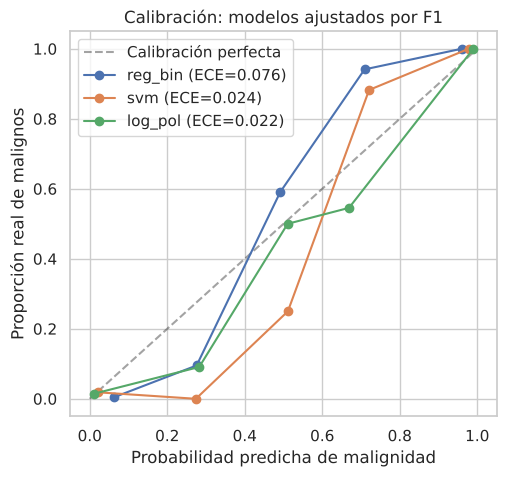

In [19]:
# Probabilidades fuera de fold de los pipelines de la sección 7 (hiperparámetros elegidos por F1)
oof_prev = {m: out_of_fold_probabilities(p, data.X_train, data.y_train) for m, p in pipes.items()}

def dibujar_calibracion(oofs, titulo):
    """Diagrama de fiabilidad: probabilidad predicha frente a proporción real de malignos."""
    fig, ax = plt.subplots(figsize=(5.5, 5))
    ax.plot([0, 1], [0, 1], "k--", alpha=.4, label="Calibración perfecta")
    for nombre, oof in oofs.items():
        curva = reliability_curve(oof.y_true, oof.mean_proba)
        ece = np.mean(oof.per_repeat(expected_calibration_error))
        ax.plot([b["mean_predicted"] for b in curva], [b["observed_frequency"] for b in curva],
                "o-", label=f"{nombre} (ECE={ece:.3f})")
    ax.set_xlabel("Probabilidad predicha de malignidad"); ax.set_ylabel("Proporción real de malignos")
    ax.set_title(titulo); ax.legend()
    plt.show()

dibujar_calibracion(oof_prev, "Calibración: modelos ajustados por F1")

**Lectura:** `reg_bin` (C = 0.0316, regularización muy fuerte) es el peor calibrado: sus probabilidades se quedan "en el medio". Por ejemplo, cuando predice ~70 % la proporción real de malignos es mucho mayor. Para una app que muestra porcentajes, esto es un problema.

### 9.2 Reentrenamiento por log-loss y umbral clínico
Para cada modelo:
- `GridSearchCV` (5 folds) **minimizando log-loss**;
- validación cruzada 5×5 para medir calibración y elegir el **umbral clínico**: el mayor punto de corte con sensibilidad ≥ 98 %;
- **modelo principal = menor Brier score** (mide a la vez acierto y calibración).

Tarda unos minutos (el SVM se calibra con escalado de Platt dentro de cada fold).

In [20]:
resultados = train_all(data)

# Resumen de la validación cruzada (solo entrenamiento)
pd.DataFrame({
    r["candidate"].id: {
        "Brier (↓)": r["cv"]["brier"]["mean"],
        "ECE (↓)": r["cv"]["ece"]["mean"],
        "ROC-AUC": r["cv"]["roc_auc"]["mean"],
        "Umbral clínico": r["threshold"],
        "Sensibilidad @ umbral": r["cv"]["recall_at_threshold"]["mean"],
        "Especificidad @ umbral": r["cv"]["specificity_at_threshold"]["mean"],
        "Principal": r["is_primary"],
    } for r in resultados
}).T.round(4)

,Brier (↓),ECE (↓),ROC-AUC,Umbral clínico,Sensibilidad @ umbral,Especificidad @ umbral,Principal
reg_bin,0.020134,0.014935,0.994056,0.153885,0.981176,0.938246,False
svm,0.019092,0.02,0.994568,0.243164,0.977647,0.961404,True
log_pol,0.020659,0.018016,0.993816,0.164239,0.98,0.936842,False


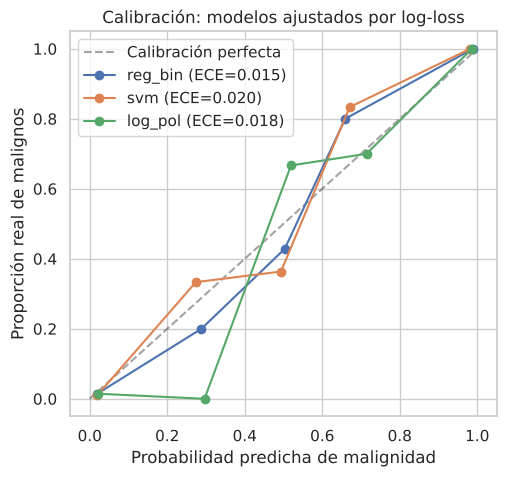

In [21]:
dibujar_calibracion({r["candidate"].id: r["oof"] for r in resultados}, "Calibración: modelos ajustados por log-loss")

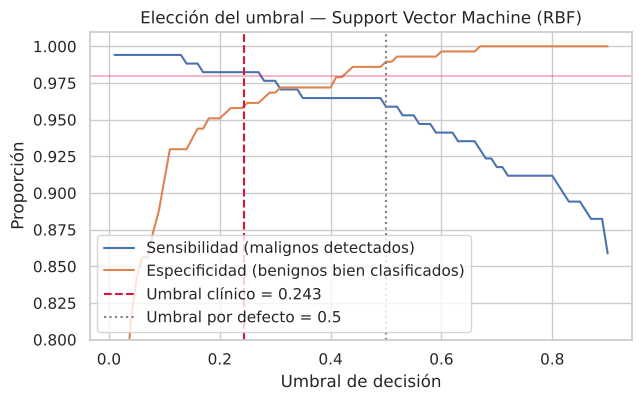

In [22]:
# Sensibilidad y especificidad según el umbral, para el modelo principal (validación cruzada)
principal = next(r for r in resultados if r["is_primary"])
p_oof, y_oof = principal["oof"].mean_proba, principal["oof"].y_true
umbrales = np.linspace(0.01, 0.9, 90)
sens = [((p_oof >= t) & (y_oof == 1)).sum() / (y_oof == 1).sum() for t in umbrales]
esp = [((p_oof < t) & (y_oof == 0)).sum() / (y_oof == 0).sum() for t in umbrales]

plt.figure(figsize=(7, 4))
plt.plot(umbrales, sens, label="Sensibilidad (malignos detectados)")
plt.plot(umbrales, esp, label="Especificidad (benignos bien clasificados)")
plt.axvline(principal["threshold"], color="crimson", ls="--", label=f"Umbral clínico = {principal['threshold']:.3f}")
plt.axvline(0.5, color="gray", ls=":", label="Umbral por defecto = 0.5")
plt.axhline(config.TARGET_RECALL, color="crimson", alpha=.3)
plt.xlabel("Umbral de decisión"); plt.ylabel("Proporción"); plt.ylim(0.8, 1.01)
plt.title(f"Elección del umbral — {principal['candidate'].name}"); plt.legend(loc="lower left")
plt.show()

### 9.3 Evaluación final en el conjunto de prueba (una sola vez)

In [23]:
filas = {}
for r in resultados:
    for etiqueta, m in (("umbral clínico", r["test"]), ("umbral 0.5", r["test_default_threshold"])):
        cm = m["confusion_matrix"]
        filas[(r["candidate"].id, etiqueta)] = {
            "Umbral": m["threshold"], "Sensibilidad": m["recall"], "Especificidad": m["specificity"],
            "Precision": m["precision"], "F1": m["f1"],
            "Falsos negativos": cm["false_negative"], "Falsos positivos": cm["false_positive"]}
pd.DataFrame(filas).T.round(4)

Umbral  Sensibilidad  Especificidad  Precision  \
reg_bin umbral clínico  0.1539        0.9762         0.9444     0.9111   
        umbral 0.5      0.5000        0.9524         0.9861     0.9756   
svm     umbral clínico  0.2432        0.9762         0.9861     0.9762   
        umbral 0.5      0.5000        0.9524         1.0000     1.0000   
log_pol umbral clínico  0.1642        0.9524         0.9583     0.9302   
        umbral 0.5      0.5000        0.9524         0.9722     0.9524   

                            F1  Falsos negativos  Falsos positivos  
reg_bin umbral clínico  0.9425               1.0               4.0  
        umbral 0.5      0.9639               2.0               1.0  
svm     umbral clínico  0.9762               1.0               1.0  
        umbral 0.5      0.9756               2.0               0.0  
log_pol umbral clínico  0.9412               2.0               3.0  
        umbral 0.5      0.9524               2.0               2.0

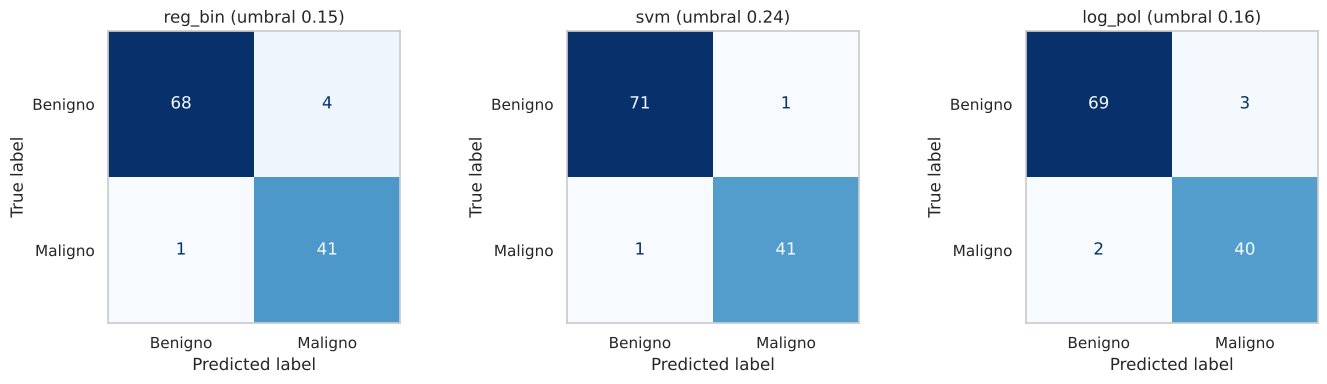

In [24]:
# Matrices de confusión con el umbral clínico de cada modelo
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for ax, r in zip(axes, resultados):
    pred = (r["pipeline"].predict_proba(data.X_test)[:, 1] >= r["threshold"]).astype(int)
    ConfusionMatrixDisplay.from_predictions(data.y_test, pred, display_labels=["Benigno", "Maligno"],
                                            cmap="Blues", colorbar=False, ax=ax)
    ax.set_title(f"{r['candidate'].id} (umbral {r['threshold']:.2f})"); ax.grid(False)
plt.tight_layout(); plt.show()

### 9.4 Conclusión y modelo final
- Ajustar por **log-loss** deja los tres modelos bien calibrados (ECE ≈ 0.015–0.020, frente a 0.076 del `reg_bin` anterior).
- Con el **umbral clínico**, los tres alcanzan ~98 % de sensibilidad en validación cruzada.
- **Modelo final de la aplicación: `svm`.** Tiene el menor Brier score y, a la misma sensibilidad, comete menos falsos positivos (especificidad ~96 % frente a ~94 % en validación cruzada). En el test detecta 41 de los 42 malignos con un solo falso positivo.
- Las diferencias entre los tres modelos son pequeñas (dentro de la variación entre folds). La app muestra los tres como **consenso**, y `svm` es el que decide.
- Modelos de árboles y KNN se compararon con validación cruzada anidada en `ml/reports/benchmark.md` y quedaron por debajo.

### 9.5 Exportación para la aplicación
Se exportan los tres pipelines (escalado + modelo) con `joblib`, junto con su umbral y sus métricas, a `backend/artifacts/`. La API (FastAPI) los carga al arrancar.

In [25]:
comparacion = export(resultados, data)
print("Modelo principal:", comparacion["primary_model"])
print("Archivos:", sorted(str(p.relative_to(ROOT)) for p in (config.ARTIFACTS_DIR).rglob("*.*")))

# Verificación: recargar el pipeline exportado y predecir dos casos del test
modelo = joblib.load(config.ARTIFACTS_DIR / "models" / comparacion["primary_model"] / "pipeline.joblib")
umbral = next(m["threshold"] for m in comparacion["models"] if m["is_recommended"])
proba = modelo.predict_proba(data.X_test.head(2))[:, 1]
for p, real in zip(proba, data.y_test.head(2)):
    print(f"P(maligno) = {p:.3f} -> {'Maligno' if p >= umbral else 'Benigno'} (real: {'Maligno' if real else 'Benigno'})")

Modelo principal: svm
Archivos: ['backend/artifacts/comparison.json', 'backend/artifacts/metadata.json', 'backend/artifacts/models/log_pol/pipeline.joblib', 'backend/artifacts/models/reg_bin/pipeline.joblib', 'backend/artifacts/models/svm/pipeline.joblib']
P(maligno) = 0.000 -> Benigno (real: Benigno)
P(maligno) = 1.000 -> Maligno (real: Maligno)
